# Motif Enrichment

## Setup

Download a **MEME motif database file** containing human transcription factor binding motifs from the Cis-BP resource, alongside the **human genome** in fasta format.



In [1]:
%%bash
[ -f data/cisBP_human.meme ] || wget -O data/cisBP_human.meme https://osf.io/download/uk6vn
[ -f data/GRCh38.fa ] || wget -O data/GRCh38.fa.gz https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_38/GRCh38.p13.genome.fa.gz
[ -f data/GRCh38.fa ] || gunzip -c data/GRCh38.fa.gz > data/GRCh38.fa

In [2]:
import gatac as ga
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

sc.set_figure_params(dpi=100, frameon=False)

GENOME_FASTA = "data/GRCh38.fa"
MOTIF_FILE   = "data/cisBP_human.meme"

peak_adata = ad.read_h5ad("data/pbmc_peaks.h5ad")
print(peak_adata)

AnnData object with n_obs × n_vars = 5001 × 194467
    obs: 'barcode', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction', 'leiden', 'cell_type'
    obsm: 'X_umap'
    layers: None (.X)


## 1. Load motifs

In [3]:
motifs = ga.motif.read(MOTIF_FILE, unique=True)
print(f"Loaded {len(motifs)} motifs")

# Inspect a single motif
m = motifs[0]
print(f"\nExample motif:")
print(f"  ID:     {m.id}")
print(f"  Name:   {m.name}")
print(f"  Family: {m.family}")
print(f"  Length: {m.pwm.shape[0]} bp")
print(f"  Info:   {m.info_content():.2f} bits")

Loaded 1165 motifs

Example motif:
  ID:     AC023509.3+M02872_2.00
  Name:   AC023509.3
  Family: None
  Length: 14 bp
  Info:   17.31 bits


In [4]:
peaks = ga.peak.markers(adata=peak_adata, groupby="leiden")

markers = {}
for leiden, df in peaks.items():
    markers[leiden] = df.loc[df.log2_fc > 0][:1000].feature.values.tolist()

14:03:49 - gatac.peak.markers - INFO - Running marker peak detection for groups in 'leiden'


14:03:50 - gatac.peak.markers - INFO - Testing 12 groups, 194,467 features, 5,001 cells


14:03:50 - gatac.peak.markers - INFO - Using max_cells=500 per group for balanced comparison


14:03:52 - gatac.peak.markers - INFO - Marker peak detection complete. Results stored in adata.uns['marker_peaks']


## 2. Run motif enrichment

In [5]:
import time
import numpy as np

t0 = time.perf_counter()
enrichment_results = ga.motif.enrichment(
    motifs,
    regions=markers,
    genome_fasta=GENOME_FASTA,
)
print(f"Motif enrichment in {time.perf_counter() - t0:.1f}s")


14:03:52 - gatac.motif.motif - INFO - Fetching 8973 sequences...


14:03:52 - gatac.motif.motif - INFO - Encoding sequences for GPU...


14:03:52 - gatac.motif.motif - INFO - Precomputing score thresholds for all motifs...


14:03:54 - gatac.motif.motif - INFO - Scanning 1165 motifs across 8973 regions...


Motifs:   0%|          | 0/1165 [00:00<?, ?it/s]

14:04:09 - gatac.motif.motif - INFO - Motif enrichment analysis complete


Motif enrichment in 17.1s


In [6]:
enrichment_results["0"].sort_values("adjusted p-value").head()

,id,name,family,log2(fold change),p-value,adjusted p-value
770,TFDP1+M08108_2.00,TFDP1,None,1.604875,0.282076,0.984806
779,TGIF2LY+M05313_2.00,TGIF2LY,None,-inf,0.728142,0.984806
778,TGIF2LX+M05194_2.00,TGIF2LX,None,-inf,0.748997,0.984806
777,TGIF2+M03123_2.00,TGIF2,None,-inf,0.614241,0.984806
776,TGIF1+M03223_2.00,TGIF1,None,-inf,0.630163,0.984806


## 3. Visualize top enriched motifs

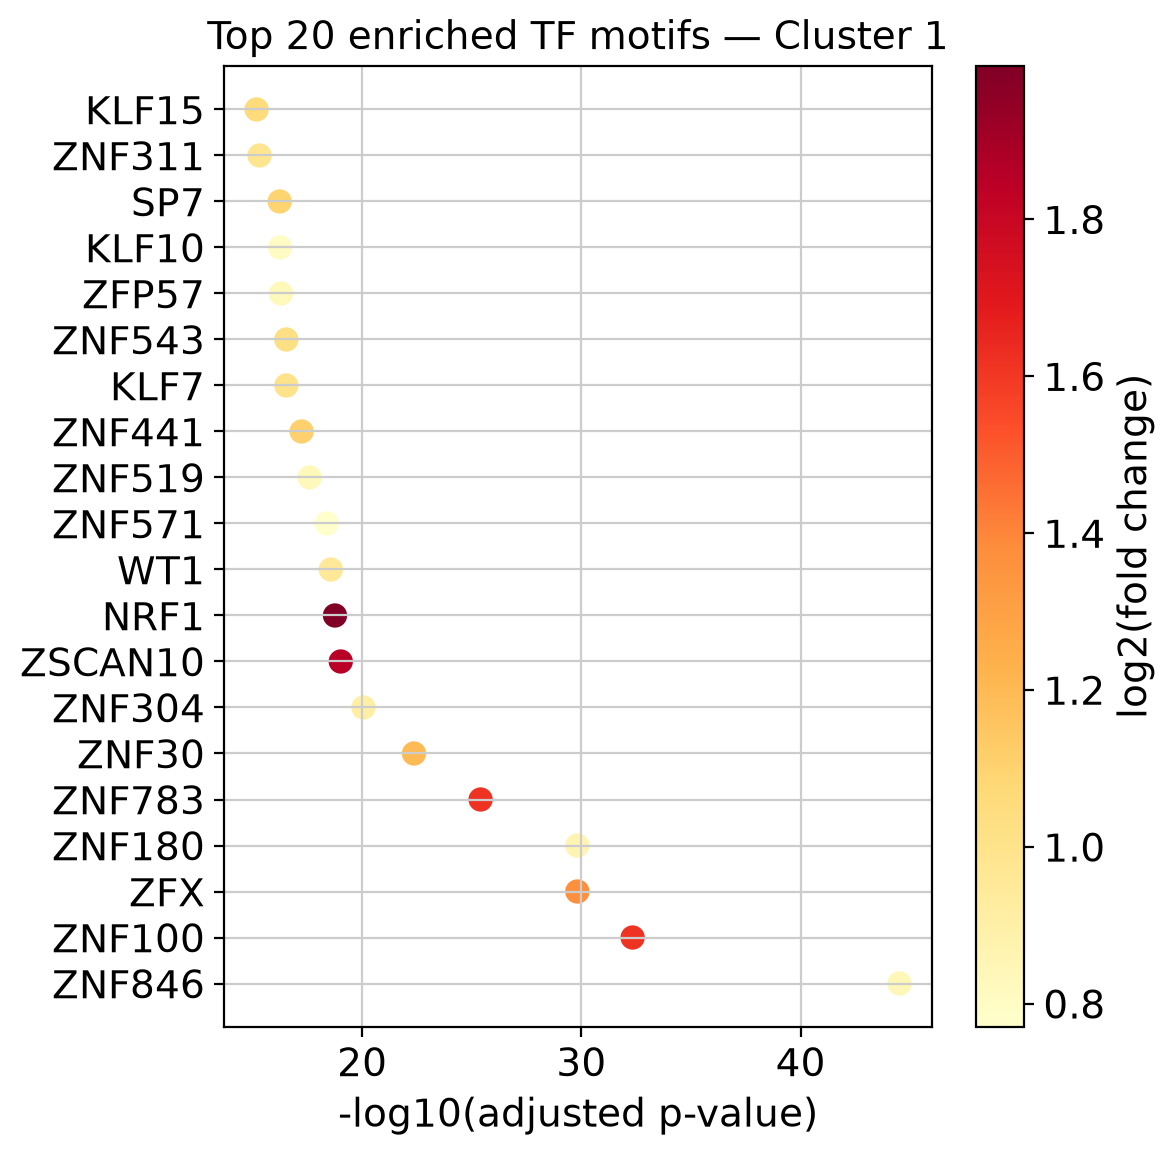

In [7]:
# Show top 20 enriched motifs for a chosen cluster
cluster_id = "1"
df = enrichment_results[cluster_id]

top20 = df.nsmallest(20, "adjusted p-value")

fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(
    -np.log10(top20["adjusted p-value"] + 1e-300),
    range(len(top20)),
    c=top20["log2(fold change)"],
    cmap="YlOrRd",
    s=60,
)
plt.colorbar(sc, ax=ax, label="log2(fold change)")
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20["name"])
ax.set_xlabel("-log10(adjusted p-value)")
ax.set_title(f"Top 20 enriched TF motifs — Cluster {cluster_id}")
plt.tight_layout()
plt.show()


## Next steps

- [04 – chromVAR](04_chromvar.ipynb): per-cell TF activity scores
- [05 – GSEA](05_gsea.ipynb): preranked GSEA on motif gene sets